# CHARGED PARTICLE IN MAGNETIC FIELD

In [2]:
from matplotlib import pyplot as plt
import numpy as np
import scipy
from matplotlib.animation import PillowWriter
from mpl_toolkits.mplot3d import Axes3D

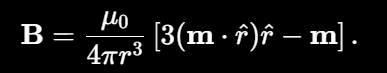

$\vec{m} = (0,0,m)$

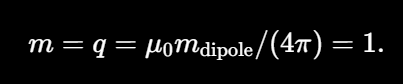

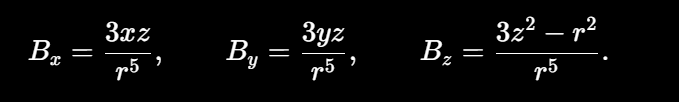

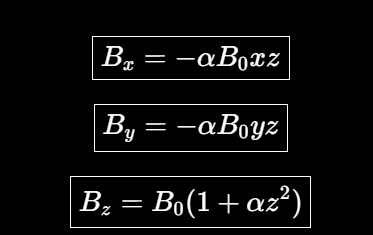

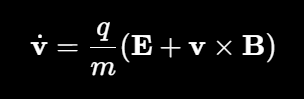

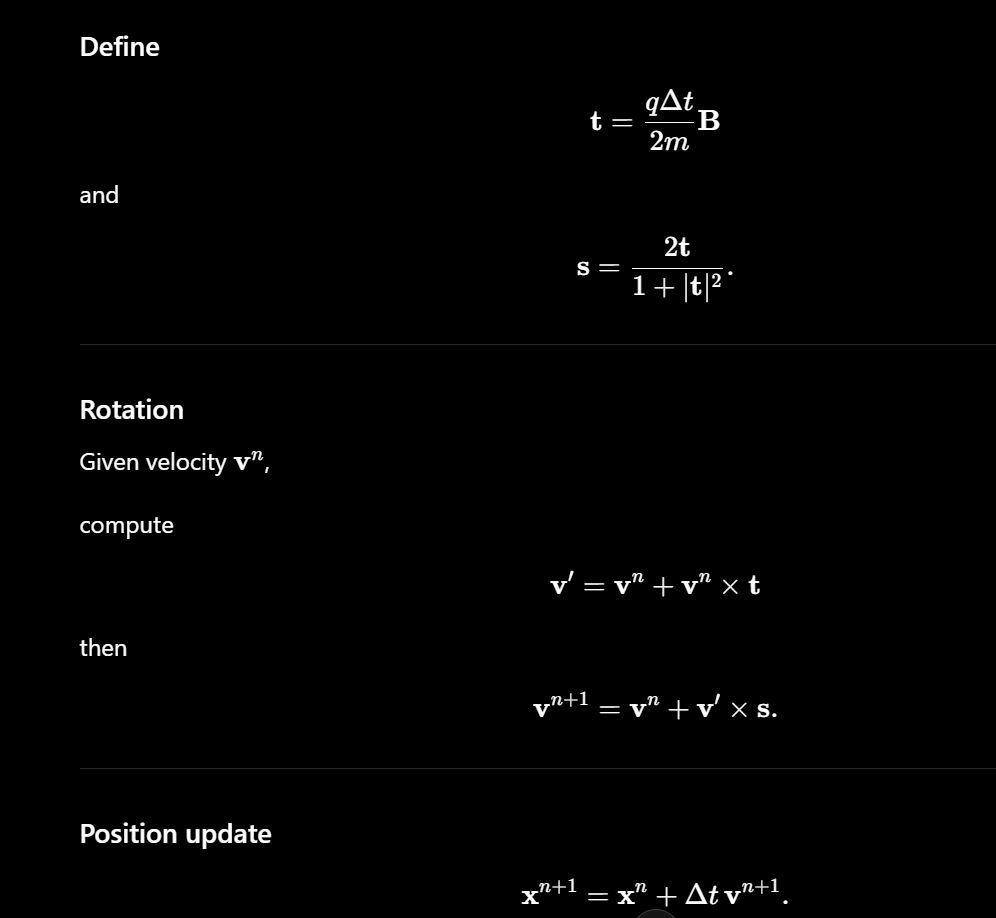

In [3]:
B0 = 1.0
alpha = 0.05

In [4]:
def calc_B(r):
    rmod = np.linalg.norm(r)
    B = np.zeros(3)
    #dipole
    #B[0] = 3*r[0]*r[2]/rmod**5.
    #B[1] = 3*r[1]*r[2]/rmod**5.
    #B[2]  = (3*r[2]**2. - rmod**2.)/rmod**5.

    #gyro
    #B[2] = -3.

    #magnetic mirror machine
    B[0] = -alpha*B0*r[0]*r[2]
    B[1] = -alpha*B0*r[1]*r[2]
    B[2] = B0*(1. + alpha*r[2]**2.)

    return B


## Particle

In [5]:
def cross_product(a, b):
    c = np.zeros(3)
    c[0] = a[1]*b[2] - a[2]*b[1]
    c[1] = - (a[0]*b[2] - a[2]*b[0])
    c[2] = a[0]*b[1] - a[1]*b[0]
    return c

In [6]:
class particle_magnetic_field():
    def __init__(self, t):
        self.q = 1.
        self.m = 1.
        self.t = t
        self.dt = self.t[1] - self.t[0]
        self.r = np.zeros((3, len(t)))
        self.v = np.zeros((3, len(t)))
        self.vmod = np.zeros(len(t))

    def set_initial_data(self, r0, v0):
        self.r[:, 0] = r0
        self.v[:, 0] = v0
        self.vmod[0] = np.linalg.norm(self.v[:,0])
        

    def time_evolve(self):
        for i in range(0, len(self.t)-1):
            
            t = self.q*calc_B(self.r[:,i])*self.dt/(2*self.m)
            s = 2*t/(1 + np.linalg.norm(t)**2.)

            vprime = self.v[:, i] + cross_product(self.v[:, i], t)
            self.v[:, i+1] = self.v[:, i]+ cross_product(vprime, s)
            self.r[:, i+1] = self.r[:, i]+ self.v[:, i+1]*self.dt

            self.vmod[i+1] = np.linalg.norm(self.v[:,i+1])



In [195]:
r0 = np.array([0.5, 0., 0.])
v0 = np.array([0., 0.5, 0.2])
#v0 = np.array([0., 0.3, 0.])

time = np.linspace(0, 130, int(130/0.01 + 1))

particle = particle_magnetic_field(time)

In [196]:
particle.set_initial_data(r0, v0)

In [197]:
particle.time_evolve()

C:\Users\Ayush Roy\AppData\Local\Temp\ipykernel_32236\1475360892.py:1: RuntimeWarning: divide by zero encountered in log10
  plt.plot(particle.t, np.log10(np.abs((1 - particle.vmod/particle.vmod[0]))))


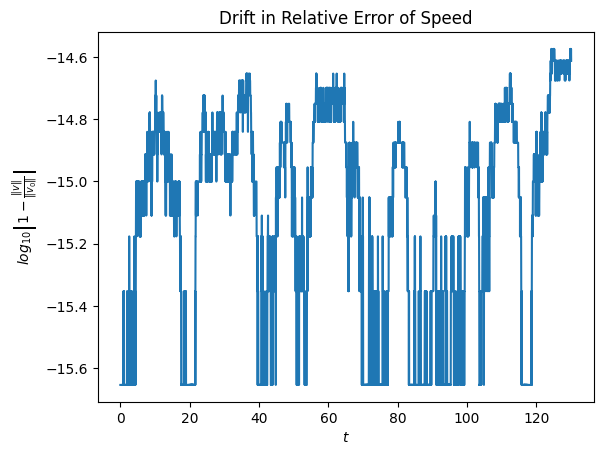

In [198]:
plt.plot(particle.t, np.log10(np.abs((1 - particle.vmod/particle.vmod[0]))))
plt.title('Drift in Relative Error of Speed')
plt.xlabel(r'$t$')
plt.ylabel(r'$log_{10}\left|1 - \frac{\|v\|}{\|v_0\|}\right|$')
plt.show()

In [199]:
np.min(particle.r[0,:]), np.max(particle.r[0,:])

(0.4659212420261, 1.5060564607561853)

In [200]:
np.min(particle.r[1,:]), np.max(particle.r[1,:])

(-0.5023143167295685, 0.53728907373026)

In [201]:
np.min(particle.r[2,:]), np.max(particle.r[2,:])

(-1.7448718853947591, 1.7486095336563399)

## Field Lines

$$ \frac{d\vec{x}}{d \tau} = \vec{B}(\vec{x})$$

In [202]:
def fieldline_rhs(r):
    x,y,z = r

    Bx = -alpha*B0*x*z
    By = -alpha*B0*y*z
    Bz = B0*(1 + alpha*z**2)

    Bmag = np.sqrt(Bx**2 + By**2 + Bz**2)

    return np.array([Bx,By,Bz])/Bmag

In [203]:


def solve_fieldline(x0):
    tau = np.linspace(0,50, int(50/0.01 + 1))
    dtau = tau[1] - tau[0]
    x_forward = np.zeros((3, len(tau)))
    x_forward[:, 0] = x0
    for i in range(0, len(tau)-1):
        x_forward[:,i+1] = x_forward[:,i] + dtau*fieldline_rhs(x_forward[:,i])
    
    tau = np.linspace(0,-50, int(50/0.01 + 1))
    dtau = tau[1] - tau[0]
    x_backward = np.zeros((3, len(tau)))
    x_backward[:, 0] = x0
    for i in range(0, len(tau)-1):
        x_backward[:,i+1] = x_backward[:,i] + dtau*fieldline_rhs(x_backward[:,i])


    return np.concatenate((np.flip(x_backward, axis=1), x_forward), axis = 1)
    


In [204]:
fieldlines = []

for i in range(0, 9):
    fieldlines.append(solve_fieldline(np.array([0.6 + i*0.1,0.,0.])))

for i in range(0, 9):
    fieldlines.append(solve_fieldline(np.array([0.6 + i*0.1,-0.25,0.])))

for i in range(0, 9):
    fieldlines.append(solve_fieldline(np.array([0.6 + i*0.1,0.25,0.])))

## Make Movie

In [205]:
def plot_frame(index, ax, angle1, angle2):
    
    

    #plot
    x = particle.r[0,index]
    y = particle.r[1,index]
    z = particle.r[2,index]

    xtraj = particle.r[0, :index + 1]
    ytraj = particle.r[1, :index + 1]
    ztraj = particle.r[2, :index + 1]
    ax.scatter(x, y, z, c ='red', s =50)
    ax.plot(xtraj, ytraj, ztraj, c ='red', linestyle='dashed', linewidth=2)

    for i in fieldlines:
        ax.plot(i[0,:], i[1,:], i[2, :], c='white', linewidth = 1)
   
    #minimum and maximum values
    ax.set_xlim([np.min(particle.r[0,:])-0.1, np.max(particle.r[0,:])+0.1])
    ax.set_ylim([np.min(particle.r[1,:])-0.1, np.max(particle.r[1,:])+0.1])
    ax.set_zlim([np.min(particle.r[2,:])-0.1, np.max(particle.r[2,:])+0.1])

    ax.text2D(0.05, 0.90, "t: " + str("%.3f"%(time[index])), size=20, c='yellow',transform=ax.transAxes)

    ax.text2D(0.05, 0.7, "vx: " + str("%.3f"%(particle.v[0,index])), size=20, c='yellow',transform=ax.transAxes)
    ax.text2D(0.05, 0.625, "vy: " + str("%.3f"%(particle.v[1,index])), size=20, c='yellow',transform=ax.transAxes)
    ax.text2D(0.05, 0.55, "vz: " + str("%.3f"%(particle.v[2,index])), size=20, c='yellow',transform=ax.transAxes)
    ax.text2D(0.05, 0.475, "|v|: " + str("%.3f"%(particle.vmod[index])), size=20, c='yellow',transform=ax.transAxes)

    ax.text2D(0.05, 0.30, "x: " + str("%.3f"%(x)), size=20, c='yellow',transform=ax.transAxes)
    ax.text2D(0.05, 0.225, "y: " + str("%.3f"%(y)), size=20, c='yellow',transform=ax.transAxes)
    ax.text2D(0.05, 0.15, "z: " + str("%.3f"%(z)), size=20, c='yellow',transform=ax.transAxes)

    #aesthetics
    ax.set_axis_off()
    ax.view_init(angle1, angle2)

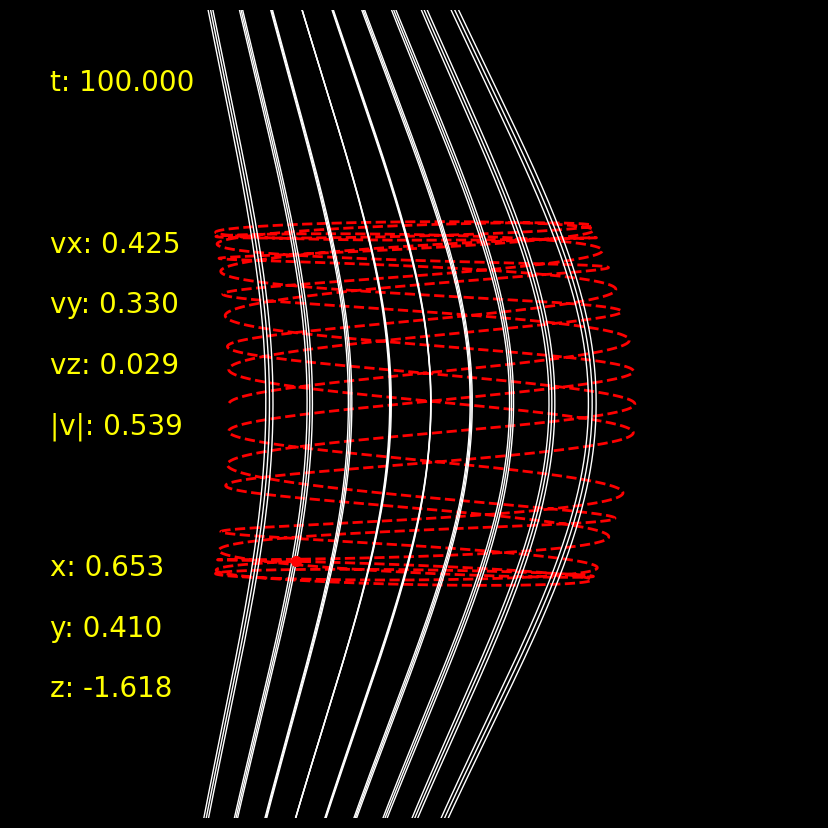

In [206]:
fig = plt.figure()

fig.set_size_inches(18.5, 10.5, forward=True)
fig.set_facecolor('black')
ax = plt.subplot(1,1,1, projection='3d')
ax.set_facecolor('black')

plot_frame(10000, ax, 0, 270)

In [167]:
metadata = dict(title='Movie', artist ='ayush_roy')
writer = PillowWriter(fps=10, metadata = metadata)

In [209]:
len(time)/50

260.02

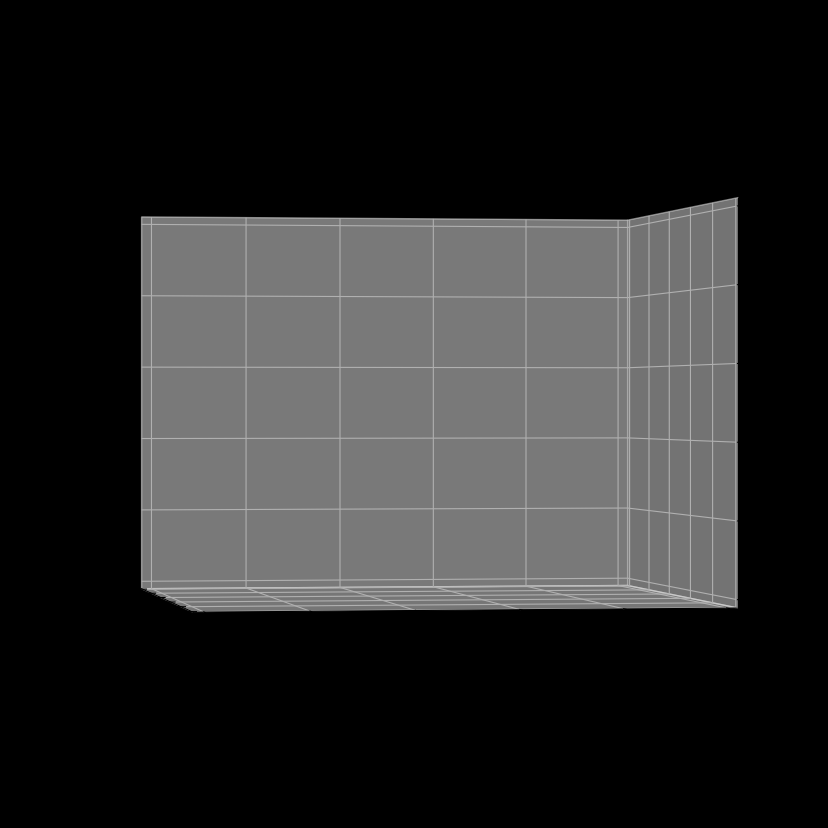

In [210]:
fig = plt.figure()

fig.set_size_inches(18.5, 10.5, forward=True)
fig.set_facecolor('black')
ax = plt.subplot(1,1,1, projection='3d')
ax.set_facecolor('black')

view_angle1 = 0
view_angle2 = 270

with writer.saving(fig, 'particle_magnetic_field.gif',100):
     for i in range(0,len(time)):
        if i%50==0:
            #if view_angle1<45:
            #    view_angle1= view_angle1 + 0.5 
         

            view_angle2 = view_angle2 + 1
            plot_frame(i, ax, view_angle1, view_angle2)
            writer.grab_frame()
            plt.cla()